# Credit Card Default Prediction

## Project Overview

This project aims to analyse credit card customer data and develop machine learning models to predict the likelihood of payment default in the following month.

The analysis will explore customer demographics, credit limits, repayment history, bill amounts, and payment behaviour to identify patterns associated with credit card default.

## Objectives

- Understand and analyse credit card customer data.
- Perform data cleaning and exploratory data analysis.
- Identify factors associated with payment default.
- Build and evaluate machine learning classification models.
- Present meaningful business insights through data visualisation and a Power BI dashboard.

## Dataset

**Source:** UCI Machine Learning Repository – Default of Credit Card Clients

**Dataset size:** 30,000 records

**Target variable:** `default.payment.next.month`

## Technology Stack

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Google Colab, Power BI and GitHub.

In [2]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Configure visualisation style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
!pip install ucimlrepo

In [4]:
# Fetch the Credit Card Default dataset from UCI

from ucimlrepo import fetch_ucirepo

credit_data = fetch_ucirepo(id=350)

print("Dataset downloaded successfully.")

Dataset downloaded successfully.


In [5]:
# Separate input features and target variable

X = credit_data.data.features
y = credit_data.data.targets

# Combine features and target into one DataFrame
df = pd.concat([X, y], axis=1)

print("Dataset loaded into DataFrame.")
print("Dataset shape:", df.shape)

Dataset loaded into DataFrame.
Dataset shape: (30000, 24)


In [6]:
# Display all dataset column names

print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'Y']


In [7]:
# Assign meaningful column names based on the UCI dataset documentation

column_names = [
    'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE',
    'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
    'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
    'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6',
    'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
    'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'
]

df.columns = column_names + ['default.payment.next.month']

print("Column names updated successfully.")
print("Total columns:", len(df.columns))
print(df.columns.tolist())

Column names updated successfully.
Total columns: 24
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default.payment.next.month']


In [8]:
df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [9]:
# Check dataset dimensions and data types

print("Dataset Shape:", df.shape)

print("\nColumn Data Types:")
print(df.dtypes)

Dataset Shape: (30000, 24)

Column Data Types:
LIMIT_BAL                     int64
SEX                           int64
EDUCATION                     int64
MARRIAGE                      int64
AGE                           int64
PAY_0                         int64
PAY_2                         int64
PAY_3                         int64
PAY_4                         int64
PAY_5                         int64
PAY_6                         int64
BILL_AMT1                     int64
BILL_AMT2                     int64
BILL_AMT3                     int64
BILL_AMT4                     int64
BILL_AMT5                     int64
BILL_AMT6                     int64
PAY_AMT1                      int64
PAY_AMT2                      int64
PAY_AMT3                      int64
PAY_AMT4                      int64
PAY_AMT5                      int64
PAY_AMT6                      int64
default.payment.next.month    int64
dtype: object


In [10]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values by Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values by Column:
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64

Total Missing Values: 0


In [11]:
# Check for exact duplicate records

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 35


In [12]:
# Display the exact duplicate records

duplicate_records = df[df.duplicated(keep=False)]

print("Total rows involved in exact duplication:", len(duplicate_records))

display(duplicate_records.head(10))


Total rows involved in exact duplication: 70


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
18,360000,2,1,1,49,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
627,230000,1,1,1,39,-1,-1,-1,-1,-1,...,660,660,660,660,660,660,660,660,660,0
839,500000,1,1,1,43,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1
1093,360000,1,2,1,41,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1
1211,160000,2,3,2,26,-1,-1,-1,-1,-1,...,390,390,390,390,390,390,390,390,390,0
1601,150000,2,1,1,31,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
1759,50000,1,2,2,26,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
1964,150000,2,1,1,38,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1
1980,150000,2,1,1,38,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1
2621,210000,2,1,2,39,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0


In [13]:
# Inspect unique values in categorical columns

categorical_columns = ['SEX', 'EDUCATION', 'MARRIAGE']

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts().sort_index())


SEX
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


In [14]:
# Analyse the target variable distribution

target_column = 'default.payment.next.month'

print("Target Variable Distribution:")
print(df[target_column].value_counts().sort_index())

print("\nTarget Variable Percentages:")
print(
    (df[target_column].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

Target Variable Distribution:
default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Target Variable Percentages:
default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64


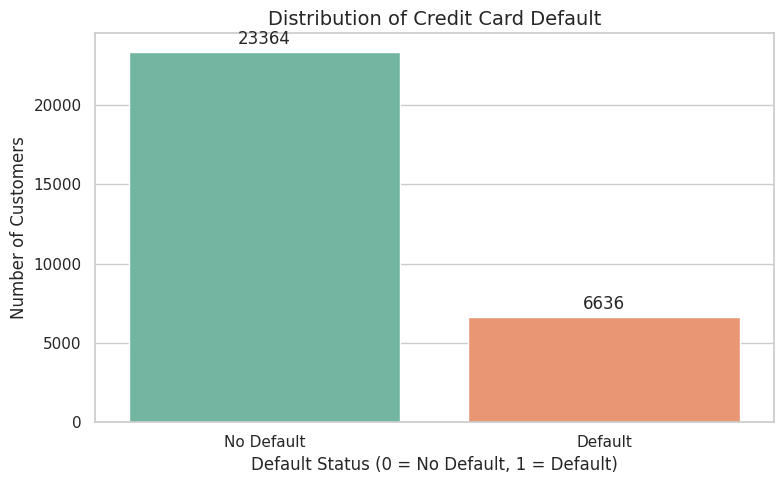

In [15]:
# Visualise the distribution of credit card defaults

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='default.payment.next.month',
    hue='default.payment.next.month',
    palette='Set2',
    legend=False
)

plt.title('Distribution of Credit Card Default', fontsize=14)
plt.xlabel('Default Status (0 = No Default, 1 = Default)')
plt.ylabel('Number of Customers')
plt.xticks([0, 1], ['No Default', 'Default'])

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()

###Target Variable Distribution

The dataset contains 30,000 credit card customers. Among them, 23,364 customers (77.88%) did not default on their payments, while 6,636 customers (22.12%) defaulted.

**Key Findings:**
- The majority of customers did not default.
- Approximately 22.12% of customers experienced payment default.
- The target variable shows class imbalance, which must be considered during model development.

**Business Insight:**

Identifying customers who are likely to default is important for credit risk management. Therefore, machine learning models should be evaluated based on their ability to identify actual defaulters, rather than relying solely on overall accuracy.

### Repayment Status and Default Analysis

**Business Question:**

How does the most recent repayment status relate to the likelihood of credit card default?

**Objective:**

To analyse the relationship between customers' repayment behaviour and their subsequent payment default, and identify repayment patterns associated with higher credit risk.

In [16]:
# Calculate default rate by most recent repayment status

repayment_analysis = (
    df.groupby('PAY_0')['default.payment.next.month']
    .agg(['count', 'sum', 'mean'])
    .reset_index()
)

repayment_analysis.columns = [
    'Repayment Status',
    'Total Customers',
    'Defaulted Customers',
    'Default Rate'
]

repayment_analysis['Default Rate'] = (
    repayment_analysis['Default Rate'] * 100
).round(2)

display(repayment_analysis)

,Repayment Status,Total Customers,Defaulted Customers,Default Rate
0,-2,2759,365,13.23
1,-1,5686,954,16.78
2,0,14737,1888,12.81
3,1,3688,1252,33.95
4,2,2667,1844,69.14
5,3,322,244,75.78
6,4,76,52,68.42
7,5,26,13,50.00
8,6,11,6,54.55
9,7,9,7,77.78


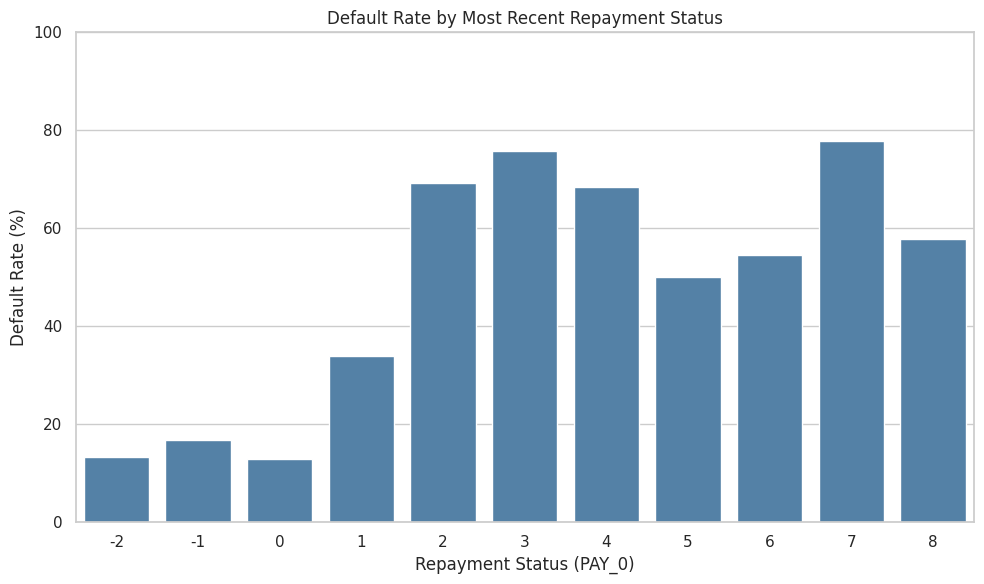

In [17]:
# Visualise default rate by repayment status

plt.figure(figsize=(10, 6))

sns.barplot(
    data=repayment_analysis,
    x='Repayment Status',
    y='Default Rate',
    color='steelblue'
)

plt.title('Default Rate by Most Recent Repayment Status')
plt.xlabel('Repayment Status (PAY_0)')
plt.ylabel('Default Rate (%)')
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

###  Repayment Status and Default Analysis

**Key Findings:**

- Customers with repayment status codes of -2, -1 and 0 have relatively lower default rates.
- The default rate increases considerably when the repayment delay status becomes positive.
- Repayment status 3 records a default rate of 75.78%.
- Categories with higher repayment status codes have relatively few observations, so their default percentages should be interpreted cautiously.

**Business Insight:**

Recent repayment behaviour is an important indicator of credit risk. Customers with a history of delayed payments may require closer monitoring and appropriate credit risk assessment.

**Conclusion:**

The analysis indicates an association between repayment delays and subsequent credit card default. This feature may provide useful predictive information for the machine learning models.

In [18]:
# Analyse average credit limit by default status

credit_limit_analysis = (
    df.groupby('default.payment.next.month')['LIMIT_BAL']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(2)
)

credit_limit_analysis.index = ['No Default', 'Default']

display(credit_limit_analysis)

,count,mean,median,min,max
No Default,23364,178099.73,150000.0,10000,1000000
Default,6636,130109.66,90000.0,10000,740000


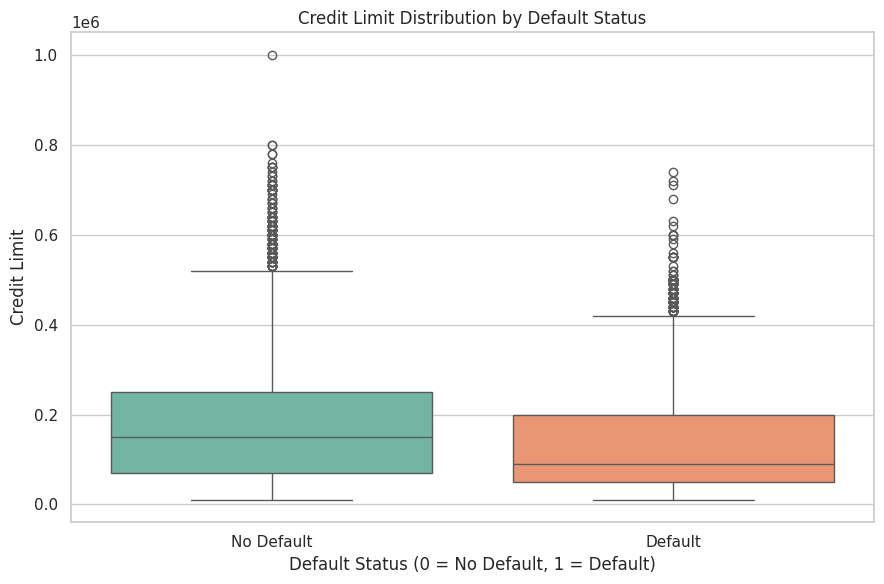

In [19]:
# Compare credit limits across default categories

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x='default.payment.next.month',
    y='LIMIT_BAL',
    hue='default.payment.next.month',
    palette='Set2',
    legend=False
)

plt.title('Credit Limit Distribution by Default Status')
plt.xlabel('Default Status (0 = No Default, 1 = Default)')
plt.ylabel('Credit Limit')
plt.xticks([0, 1], ['No Default', 'Default'])

plt.tight_layout()
plt.show()

###  Credit Limit and Default Analysis

**Key Findings:**

- Customers who did not default had an average credit limit of approximately 178,099.73.
- Customers who defaulted had a lower average credit limit of approximately 130,109.66.
- The median credit limit was 150,000 for non-default customers and 90,000 for default customers.
- Both groups contain high-value credit limit observations.

**Business Insight:**

Credit limit appears to be associated with customer default behaviour. Customers with lower credit limits showed a lower median credit limit in the default group. However, credit limit alone cannot determine whether a customer will default.

**Conclusion:**

Credit limit is a potentially useful feature for predicting credit card default. The observed outliers will be investigated during the data preprocessing stage rather than removed without justification.

In [20]:
# Analyse customer age by default status

age_analysis = (
    df.groupby('default.payment.next.month')['AGE']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(2)
)

age_analysis.index = ['No Default', 'Default']

display(age_analysis)

,count,mean,median,min,max
No Default,23364,35.42,34.0,21,79
Default,6636,35.73,34.0,21,75


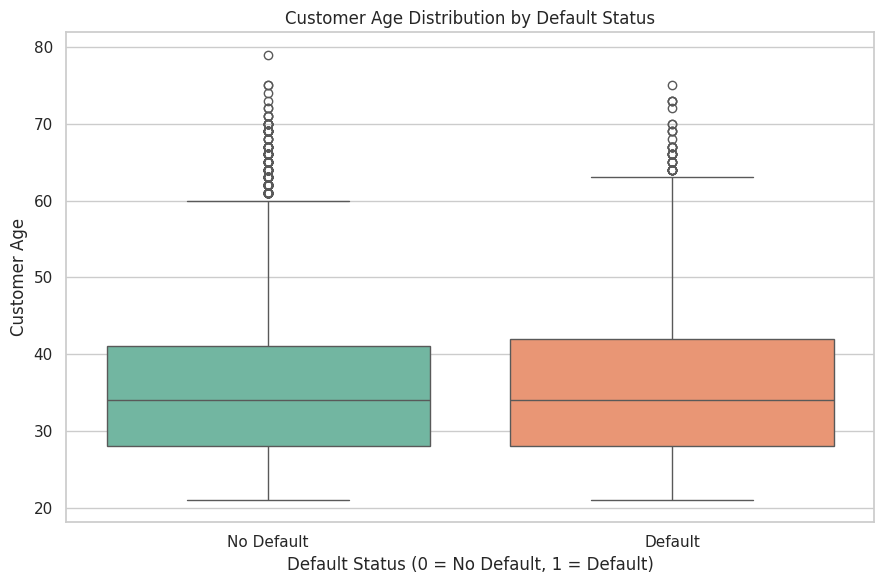

In [21]:
# Compare customer age distributions by default status

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x='default.payment.next.month',
    y='AGE',
    hue='default.payment.next.month',
    palette='Set2',
    legend=False
)

plt.title('Customer Age Distribution by Default Status')
plt.xlabel('Default Status (0 = No Default, 1 = Default)')
plt.ylabel('Customer Age')
plt.xticks([0, 1], ['No Default', 'Default'])

plt.tight_layout()
plt.show()

###  Customer Age and Default Analysis

**Key Findings:**

- The average age of non-defaulting customers is 35.42 years.
- The average age of defaulting customers is 35.73 years.
- Both groups have the same median age of 34 years.
- The age distributions are broadly similar, with some higher-age observations in both groups.

**Business Insight:**

Customer age alone does not show a strong descriptive difference between defaulting and non-defaulting customers. Other financial and repayment-related characteristics may provide more useful indicators of credit risk.

**Conclusion:**

Age will be retained as a candidate predictive feature and its contribution will be assessed during feature selection and model evaluation.

In [22]:
# Compare bill amounts and payment amounts by default status

financial_columns = [
    'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
    'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6',
    'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
    'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'
]

financial_analysis = (
    df.groupby('default.payment.next.month')[financial_columns]
    .mean()
    .round(2)
)

financial_analysis.index = ['No Default', 'Default']

display(financial_analysis.T)

,No Default,Default
BILL_AMT1,51994.23,48509.16
BILL_AMT2,49717.44,47283.62
BILL_AMT3,47533.37,45181.60
BILL_AMT4,43611.17,42036.95
BILL_AMT5,40530.45,39540.19
BILL_AMT6,39042.27,38271.44
PAY_AMT1,6307.34,3397.04
PAY_AMT2,6640.47,3388.65
PAY_AMT3,5753.50,3367.35
PAY_AMT4,5300.53,3155.63


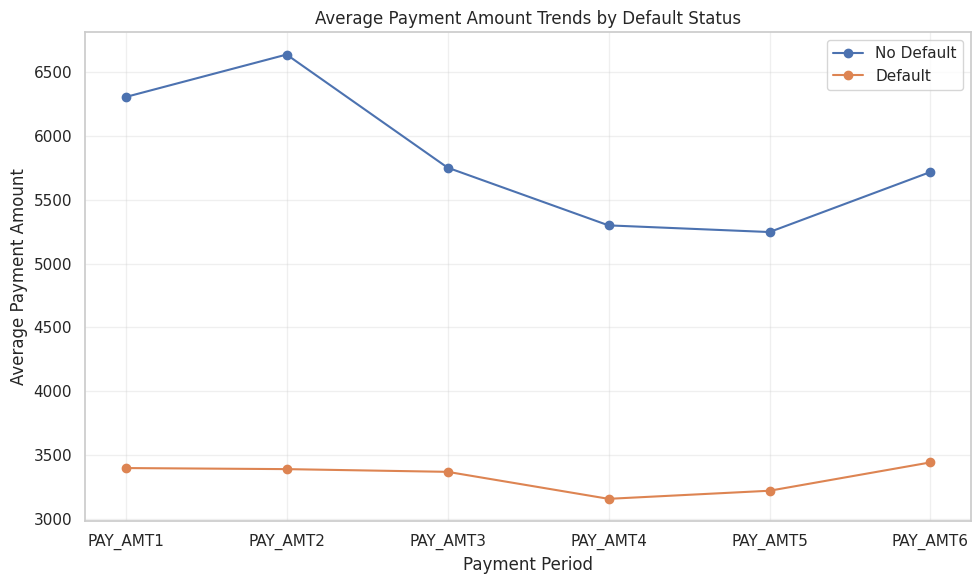

In [23]:
# Compare average payment trends by default status

payment_columns = [
    'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
    'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'
]

payment_trends = (
    df.groupby('default.payment.next.month')[payment_columns]
    .mean()
    .T
)

plt.figure(figsize=(10, 6))

plt.plot(
    payment_trends.index,
    payment_trends[0],
    marker='o',
    label='No Default'
)

plt.plot(
    payment_trends.index,
    payment_trends[1],
    marker='o',
    label='Default'
)

plt.title('Average Payment Amount Trends by Default Status')
plt.xlabel('Payment Period')
plt.ylabel('Average Payment Amount')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

###  Bill Statement and Payment Amount Analysis

**Key Findings:**

- Non-defaulting customers have slightly higher average bill amounts across all six recorded periods.
- Non-defaulting customers consistently make higher average payments than defaulting customers.
- The average payment amount for non-defaulting customers peaks during the second recorded period.
- Defaulting customers show comparatively lower payment amounts throughout the observed periods.

**Business Insight:**

Payment behaviour may be an important indicator of credit risk. Customers who consistently make lower payments may require closer monitoring. Bill amounts alone show a smaller difference between the two groups.

**Conclusion:**

Payment amount features may contribute useful predictive information to the credit card default prediction model. Their importance will be evaluated during feature selection and model development.

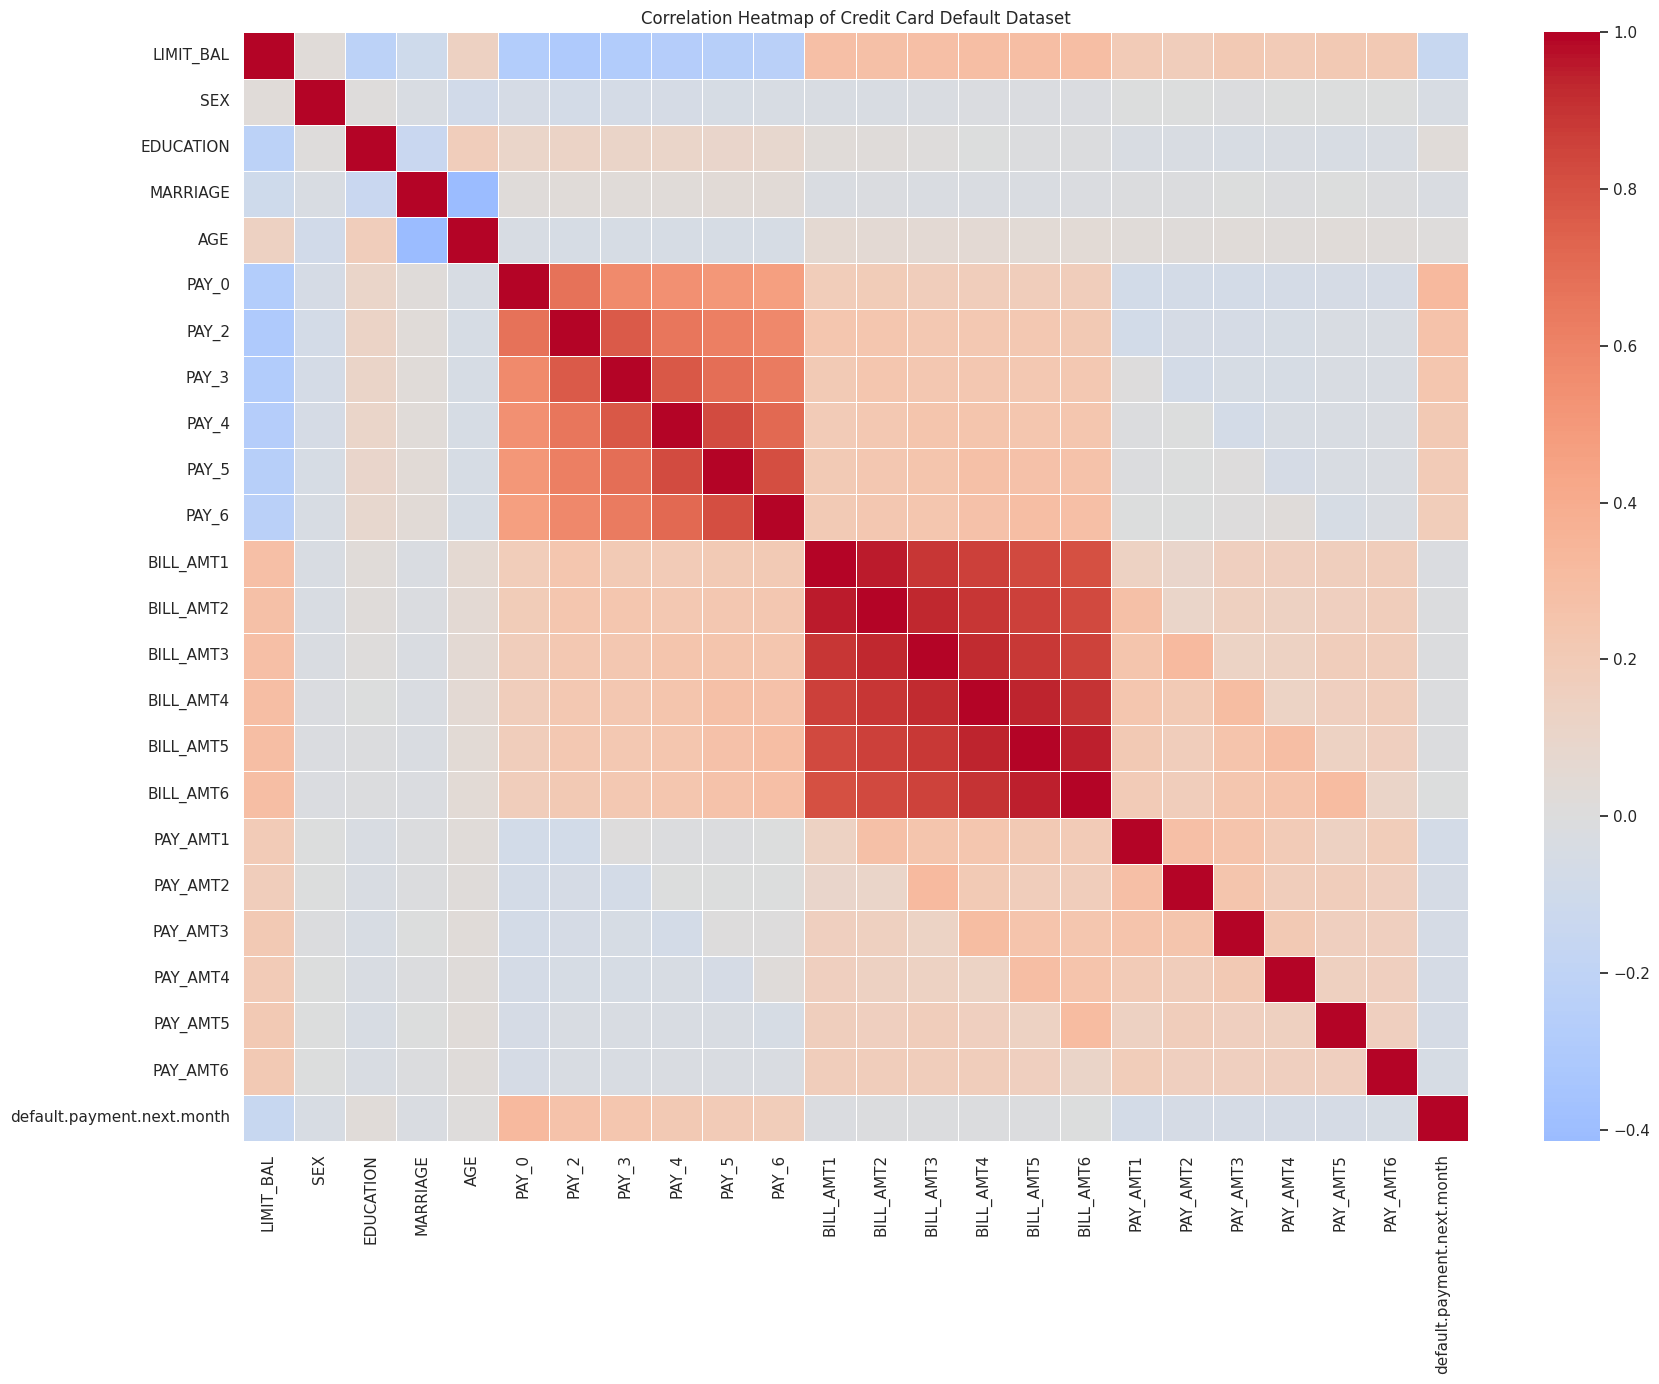

In [24]:
# Calculate correlation between all numerical features

correlation_matrix = df.corr()

# Display correlation heatmap

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Correlation Heatmap of Credit Card Default Dataset')
plt.tight_layout()
plt.show()

In [25]:
# Rank features by their correlation with the target variable

target_correlation = (
    correlation_matrix['default.payment.next.month']
    .drop('default.payment.next.month')
    .sort_values(key=abs, ascending=False)
)

print("Feature Correlation with Default:")
display(target_correlation.to_frame(name='Correlation'))

Feature Correlation with Default:


,Correlation
PAY_0,0.324794
PAY_2,0.263551
PAY_3,0.235253
PAY_4,0.216614
PAY_5,0.204149
PAY_6,0.186866
LIMIT_BAL,-0.153520
PAY_AMT1,-0.072929
PAY_AMT2,-0.058579
PAY_AMT4,-0.056827


### Correlation Analysis – Key Findings

The correlation analysis identifies repayment status as the feature group most strongly associated with credit card default.

**Key Findings:**

1. **Repayment Status:** PAY_0 has the strongest positive correlation with default (0.3248), followed by PAY_2 (0.2636) and PAY_3 (0.2353). This indicates that delayed repayment is associated with a higher likelihood of default.

2. **Credit Limit:** LIMIT_BAL has a negative correlation of -0.1535 with default, suggesting that customers with higher credit limits tend to have lower default rates in this dataset.

3. **Payment Amounts:** PAY_AMT1 has the strongest negative correlation among payment amount variables (-0.0729). The remaining payment amount variables also show weak negative correlations.

4. **Demographic Variables:** SEX, EDUCATION, MARRIAGE and AGE have relatively weak linear correlations with the target variable.

5. **Bill Amounts:** BILL_AMT1 to BILL_AMT6 have correlations close to zero with the target, indicating weak individual linear relationships.

**Business Insight:**

Repayment history appears to be more informative for identifying potential credit card defaults than individual bill amounts or demographic characteristics. Therefore, repayment status variables should receive particular attention during model development.

**Note:** Correlation does not establish causation, and weak individual correlation does not mean a feature has no predictive value.

#  Feature Engineering

Feature engineering involves preparing and transforming the dataset into a suitable format for machine learning algorithms.

##  Separation of Features and Target Variable

**Objective:**

To separate the independent variables (input features) from the dependent variable (target) before performing feature selection and model development.

In [26]:
# Separate input features and target variable

X = df.drop('default.payment.next.month', axis=1)

y = df['default.payment.next.month']

print("Feature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

Feature Dataset Shape: (30000, 23)
Target Dataset Shape: (30000,)


##  Identification of Categorical Features

Categorical variables represent distinct groups or categories. Identifying these variables is important because they require appropriate encoding before being used in machine learning models.

The categorical features identified in this dataset are SEX, EDUCATION, and MARRIAGE.

In [27]:
# Identify categorical features

categorical_features = ['SEX', 'EDUCATION', 'MARRIAGE']

print("Categorical Features:")
for column in categorical_features:
    print(f"\n{column}:")
    print(df[column].value_counts().sort_index())

Categorical Features:

SEX:
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


##  Handling Categorical Variables

The categorical variables are:

- SEX: Two categories (1 and 2).
- EDUCATION: Seven recorded categories (0 to 6).
- MARRIAGE: Four recorded categories (0 to 3).

Some values, such as 0, 5, and 6 in EDUCATION and 0 in MARRIAGE, represent unknown or undocumented categories.

These values will be retained to avoid unnecessary information loss. One-hot encoding will be applied to the categorical variables during model preprocessing.

In [28]:
# Preserve categorical features as categorical data

for column in categorical_features:
    X[column] = X[column].astype('category')

print("Categorical feature data types:")
print(X[categorical_features].dtypes)

Categorical feature data types:
SEX          category
EDUCATION    category
MARRIAGE     category
dtype: object


In [29]:
# Identify numerical features

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Total Numerical Features:", len(numerical_features))
print("\nNumerical Features:")
print(numerical_features)

Total Numerical Features: 20

Numerical Features:
['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


In [30]:
# Display feature type summary

print("Total Input Features:", X.shape[1])
print("Categorical Features:", len(categorical_features))
print("Numerical Features:", len(numerical_features))

Total Input Features: 23
Categorical Features: 3
Numerical Features: 20


In [31]:
# Combine features and target for duplicate investigation

investigation_df = X.copy()
investigation_df['target'] = y.values

# Group records by their input features
feature_groups = investigation_df.groupby(
    list(X.columns),
    observed=True,
    dropna=False
)

# Identify groups with multiple records
duplicate_groups = feature_groups.filter(
    lambda group: len(group) > 1
)

# Count groups with conflicting target labels
conflicting_groups = sum(
    group['target'].nunique() > 1
    for _, group in duplicate_groups.groupby(
        list(X.columns),
        observed=True,
        dropna=False
    )
)

print("Records belonging to duplicate feature groups:",
      len(duplicate_groups))

print("Duplicate feature groups:",
      duplicate_groups.groupby(
          list(X.columns),
          observed=True,
          dropna=False
      ).ngroups)

print("Groups with conflicting target labels:",
      conflicting_groups)

Records belonging to duplicate feature groups: 108
Duplicate feature groups: 52
Groups with conflicting target labels: 21


In [32]:
# Import StratifiedGroupKFold

from sklearn.model_selection import StratifiedGroupKFold

# Create group identifiers from identical feature records

groups = pd.util.hash_pandas_object(
    X,
    index=False
).values

# Create a group-aware stratified split

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups)
)

# Assign training and testing records

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Verify the split

train_groups = set(groups[train_idx])
test_groups = set(groups[test_idx])

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("Overlapping Feature Groups:",
      len(train_groups.intersection(test_groups)))

print("\nTraining Default Distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting Default Distribution:")
print(y_test.value_counts(normalize=True).round(4))

Training Features: (24001, 23)
Testing Features: (5999, 23)
Training Target: (24001,)
Testing Target: (5999,)
Overlapping Feature Groups: 0

Training Default Distribution:
default.payment.next.month
0    0.7777
1    0.2223
Name: proportion, dtype: float64

Testing Default Distribution:
default.payment.next.month
0    0.7833
1    0.2167
Name: proportion, dtype: float64


## Feature Selection

Feature selection identifies the most relevant input variables for machine learning. It can help reduce unnecessary complexity and improve model interpretability.

Two approaches will be explored:
1. Random Forest Feature Importance
2. SelectKBest Statistical Feature Selection

##  Feature Importance Using Random Forest

Random Forest estimates feature importance based on how much each feature contributes to reducing impurity across the decision trees.

The model will be fitted using training data only to prevent information leakage from the test dataset.

In [33]:
# Import Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

# Train Random Forest for feature importance

rf_selector = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf_selector.fit(X_train, y_train)

# Calculate feature importance

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_selector.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 10 Important Features:")
display(feature_importance.head(10))

Top 10 Important Features:


,Feature,Importance
5,PAY_0,0.100388
11,BILL_AMT1,0.062676
0,LIMIT_BAL,0.062625
4,AGE,0.062217
12,BILL_AMT2,0.055245
17,PAY_AMT1,0.051621
13,BILL_AMT3,0.051163
18,PAY_AMT2,0.050210
14,BILL_AMT4,0.049927
19,PAY_AMT3,0.048699


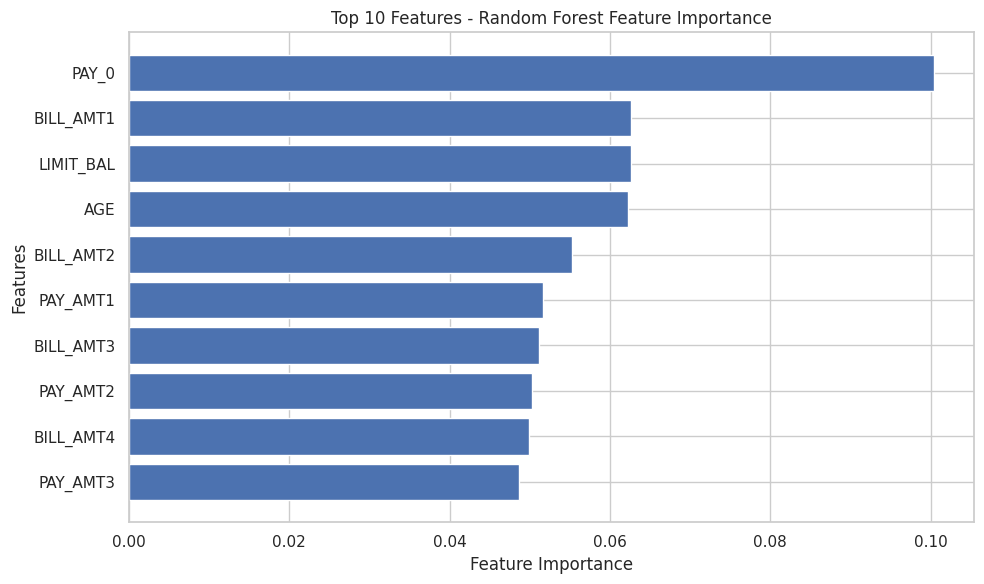

In [34]:
# Visualize the top 10 important features

top_features = feature_importance.head(10).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Top 10 Features - Random Forest Feature Importance')

plt.tight_layout()
plt.show()

##  Feature Selection Using SelectKBest

SelectKBest is a statistical feature selection technique that evaluates individual features based on their relationship with the target variable.

The ANOVA F-test (f_classif) will be used to rank the features. The top 10 features will be identified for comparison with Random Forest feature importance.

Feature selection is performed using training data only.

In [35]:
# Import SelectKBest and ANOVA F-test

from sklearn.feature_selection import SelectKBest, f_classif

# Apply SelectKBest to training data

kbest_selector = SelectKBest(
    score_func=f_classif,
    k=10
)

kbest_selector.fit(X_train, y_train)

# Create feature ranking

kbest_scores = pd.DataFrame({
    'Feature': X_train.columns,
    'F_Score': kbest_selector.scores_,
    'P_Value': kbest_selector.pvalues_
})

kbest_scores = kbest_scores.sort_values(
    by='F_Score',
    ascending=False
)

print("Top 10 Features Using SelectKBest:")
display(kbest_scores.head(10))

Top 10 Features Using SelectKBest:


,Feature,F_Score,P_Value
5,PAY_0,2918.812865,0.000000e+00
6,PAY_2,1841.445146,0.000000e+00
7,PAY_3,1482.279622,1.011931e-314
8,PAY_4,1283.103199,8.500389e-274
9,PAY_5,1142.333043,1.124580e-244
10,PAY_6,947.922430,3.499008e-204
0,LIMIT_BAL,586.631395,4.665086e-128
17,PAY_AMT1,139.278213,4.696010e-32
18,PAY_AMT2,95.872949,1.350402e-22
21,PAY_AMT5,82.807164,9.731018e-20


##  Feature Selection Summary

Two feature selection techniques were applied:

1. Random Forest Feature Importance
2. SelectKBest using ANOVA F-test

Both techniques identified PAY_0 as the most informative feature.

SelectKBest highlighted repayment-status variables, while Random Forest identified additional useful variables such as bill amounts, credit limit, and age.

All 23 features will be retained during the initial model development. This allows us to compare model performance without prematurely discarding potentially useful information.

#  Data Preprocessing

Data preprocessing transforms the input features into a suitable format for machine learning algorithms.

The following techniques will be applied:

1. One-Hot Encoding for categorical variables.
2. Standard Scaling for numerical variables when required.
3. ColumnTransformer to apply transformations to the appropriate columns.

All preprocessing transformations will be fitted using training data only to prevent data leakage.

In [36]:
# Import preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

print("Preprocessing libraries imported successfully.")

Preprocessing libraries imported successfully.


## Creating Preprocessing Pipelines

Two preprocessing configurations will be created:

1. Scaled Preprocessing: One-Hot Encoding for categorical features and Standard Scaling for numerical features. Suitable for Logistic Regression and KNN.
2. Unscaled Preprocessing: One-Hot Encoding for categorical features while retaining numerical values without scaling. Suitable for tree-based models.

The `handle_unknown='ignore'` parameter allows the encoder to handle previously unseen categories safely.

In [37]:
# Define categorical preprocessing

categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Define numerical preprocessing with scaling

numerical_transformer_scaled = StandardScaler()

# Preprocessing for models requiring scaled data

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_features),
        ('num', numerical_transformer_scaled, numerical_features)
    ]
)

# Preprocessing for tree-based models

preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numerical_features)
    ]
)

print("Scaled and unscaled preprocessing configurations created successfully.")

Scaled and unscaled preprocessing configurations created successfully.


#  Model Building

In this section, multiple supervised machine learning classification algorithms will be implemented to predict whether a credit card customer is likely to default on payment.

The following five algorithms will be evaluated:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. K-Nearest Neighbors (KNN)
5. Gradient Boosting Classifier

Each model will use an appropriate preprocessing pipeline. Model performance will be compared using classification evaluation metrics.

In [38]:
# Import classification algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

print("All five classification algorithms imported successfully.")

All five classification algorithms imported successfully.


##  Creating Machine Learning Model Pipelines

A machine learning pipeline combines preprocessing and model training into a single workflow.

This ensures that encoding and scaling are performed consistently and fitted only on the training data.

Scaled preprocessing will be used for Logistic Regression and KNN. Tree-based algorithms will use unscaled numerical features.

In [39]:
# Create machine learning model pipelines

models = {
    'Logistic Regression': Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', LogisticRegression(
            class_weight='balanced',
            max_iter=1000,
            random_state=42
        ))
    ]),

    'Decision Tree': Pipeline([
        ('preprocessor', preprocessor_unscaled),
        ('classifier', DecisionTreeClassifier(
            class_weight='balanced',
            random_state=42
        ))
    ]),

    'Random Forest': Pipeline([
        ('preprocessor', preprocessor_unscaled),
        ('classifier', RandomForestClassifier(
            n_estimators=100,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ]),

    'K-Nearest Neighbors': Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    'Gradient Boosting': Pipeline([
        ('preprocessor', preprocessor_unscaled),
        ('classifier', GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            random_state=42
        ))
    ])
}

print("Five machine learning pipelines created successfully.")

Five machine learning pipelines created successfully.


In [40]:
# Train all five machine learning models

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
    print(f"{model_name} trained successfully.\n")

print("All five models have been trained successfully.")

Training Logistic Regression...
Logistic Regression trained successfully.

Training Decision Tree...
Decision Tree trained successfully.

Training Random Forest...
Random Forest trained successfully.

Training K-Nearest Neighbors...
K-Nearest Neighbors trained successfully.

Training Gradient Boosting...
Gradient Boosting trained successfully.

All five models have been trained successfully.


## Model Evaluation

Model evaluation measures how effectively the trained classifiers predict credit card defaults on unseen data.

The following evaluation metrics will be used:

- Accuracy: Overall proportion of correct predictions.
- Precision: Proportion of predicted defaults that are actual defaults.
- Recall: Proportion of actual defaults correctly identified.
- F1-Score: Harmonic mean of precision and recall.
- ROC-AUC: Ability of the model to distinguish between the two target classes.

Confusion matrices and ROC curves will also be used to understand model performance.

In [41]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Generate predictions and calculate evaluation metrics

results = []

predictions = {}

for model_name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[model_name] = y_pred

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

print("Predictions generated and evaluation metrics calculated.")

Predictions generated and evaluation metrics calculated.


In [42]:
# Create model comparison table

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.8211,0.6596,0.3608,0.4664,0.7802
1,Logistic Regression,0.6803,0.3647,0.6408,0.4648,0.7123
2,Random Forest,0.8190,0.6583,0.3423,0.4504,0.7683
3,K-Nearest Neighbors,0.7960,0.5457,0.3492,0.4259,0.7078
4,Decision Tree,0.7318,0.3865,0.4046,0.3953,0.6135


##  Interpretation of Model Performance

Gradient Boosting achieved the highest F1-score of 0.4664 and ROC-AUC of 0.7802, making it the strongest overall candidate in the initial comparison.

Logistic Regression achieved the highest recall of 0.6408, indicating better identification of actual defaulters, but its precision was lower.

Gradient Boosting will be considered for further hyperparameter tuning, while Logistic Regression will remain an important comparison model.

## Confusion Matrix Analysis

A confusion matrix evaluates classification predictions by comparing actual and predicted classes.

It consists of four components:

- True Positive (TP): Correctly predicted defaults.
- True Negative (TN): Correctly predicted non-defaults.
- False Positive (FP): Non-defaults incorrectly predicted as defaults.
- False Negative (FN): Actual defaults incorrectly predicted as non-defaults.

Confusion matrices will be generated for all five models.

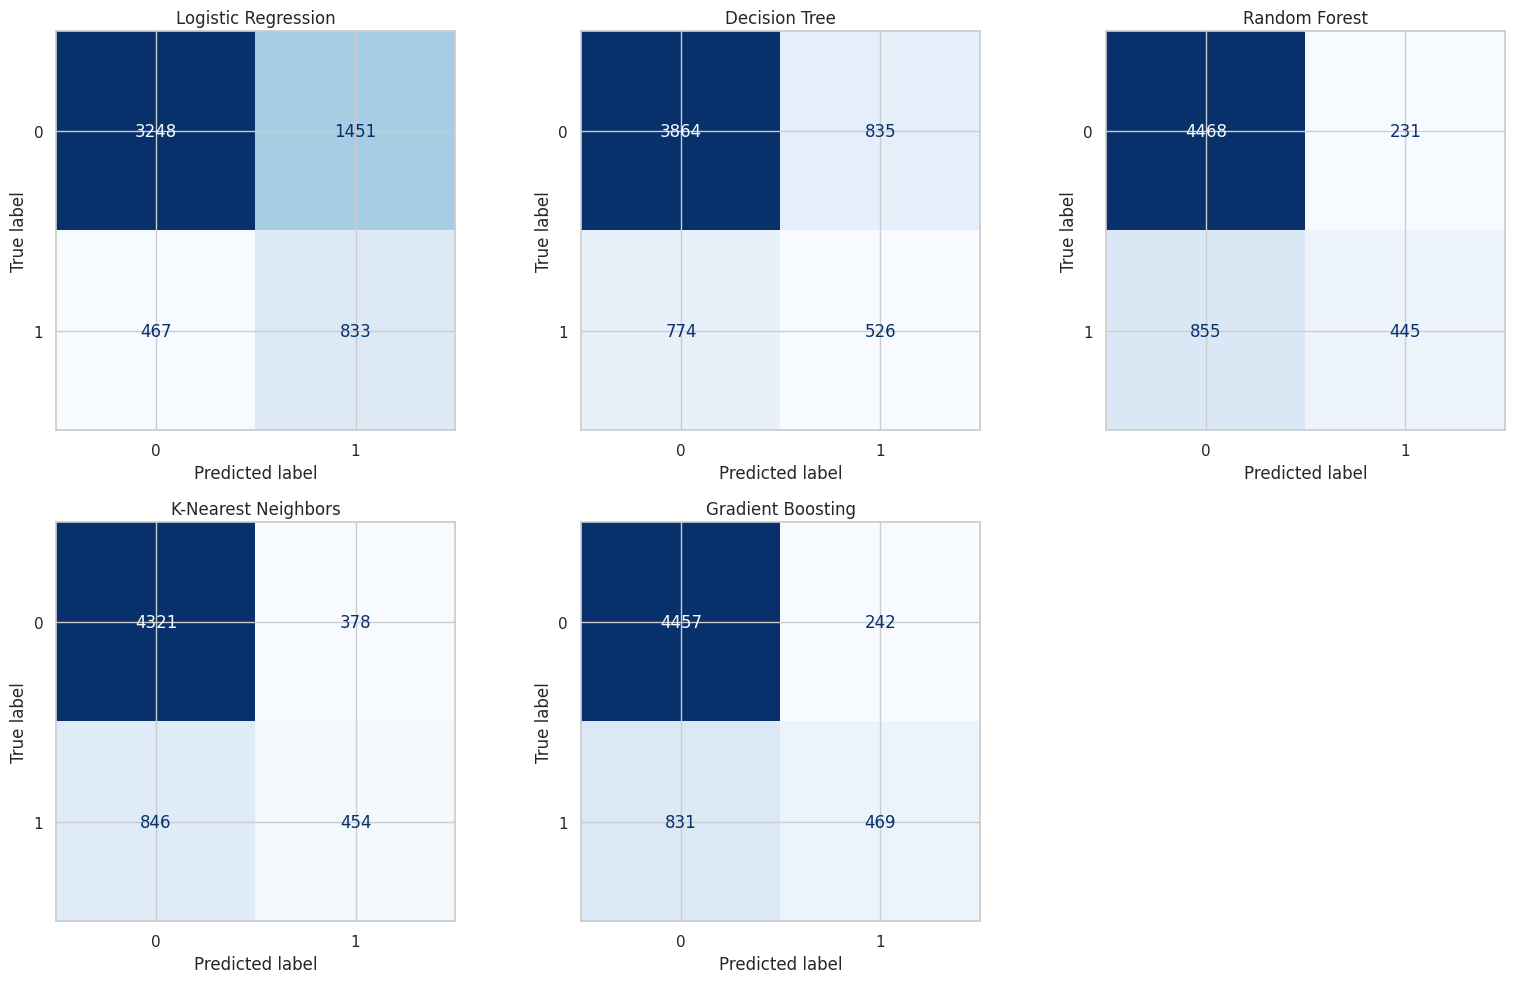

In [43]:
# Import confusion matrix visualization

from sklearn.metrics import ConfusionMatrixDisplay

# Plot confusion matrices for all models

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (model_name, y_pred) in enumerate(predictions.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        ax=axes[i],
        cmap='Blues',
        colorbar=False
    )

    axes[i].set_title(model_name)

# Remove unused subplot

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

##  Confusion Matrix Interpretation

The confusion matrices reveal differences in the classification behaviour of the five models.

Logistic Regression identifies the highest number of actual defaulters, with 833 true positives, but also produces 1,451 false positives.

Gradient Boosting achieves a better balance between identifying defaulters and limiting false positives, with 469 true positives and 242 false positives.

Random Forest produces the fewest false positives but misses a large number of actual defaulters.

These results highlight the importance of considering precision and recall together when evaluating credit default prediction models.

##  ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve evaluates the ability of a classification model to distinguish between default and non-default customers at different classification thresholds.

The Area Under the Curve (AUC) provides a summary of this performance. A higher ROC-AUC indicates better class discrimination.

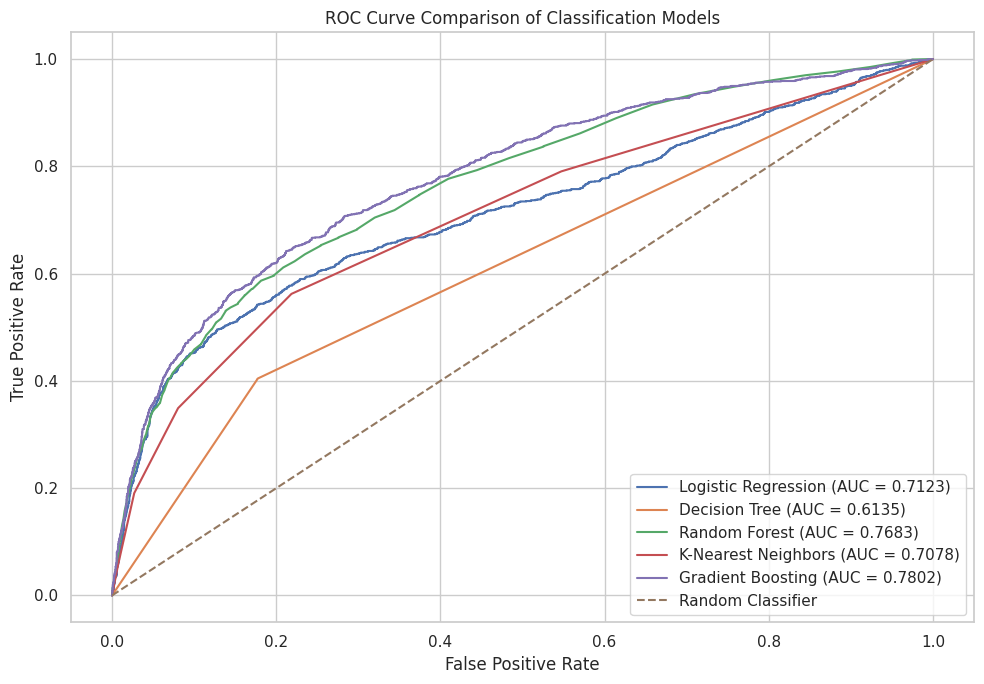

In [44]:
# Import ROC curve function

from sklearn.metrics import roc_curve, auc

# Plot ROC curves for all models

plt.figure(figsize=(10, 7))

for model_name, model in models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{model_name} (AUC = {roc_auc:.4f})'
    )

# Random classifier reference line

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison of Classification Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

##  ROC Curve Interpretation

The ROC curve comparison shows that Gradient Boosting achieved the highest ROC-AUC of 0.7802, followed by Random Forest with 0.7683.

Logistic Regression and K-Nearest Neighbors achieved ROC-AUC scores of 0.7123 and 0.7078 respectively.

Decision Tree recorded the lowest ROC-AUC of 0.6135.

Based on these results, Gradient Boosting is selected as the primary candidate for hyperparameter tuning. Logistic Regression will also be retained for comparison because it achieved the highest recall during initial evaluation.

#  Hyperparameter Tuning

Hyperparameter tuning is used to identify suitable model configurations that improve predictive performance.

Gradient Boosting and Logistic Regression will be tuned based on their initial evaluation results.

Stratified group cross-validation will be used to prevent identical feature groups from appearing in both training and validation folds.

##  Preparing Group-Aware Cross-Validation

In [45]:
# Import hyperparameter tuning tools

from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

# Obtain group identifiers corresponding to training records

groups_train = groups[train_idx]

# Create group-aware cross-validation

group_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Group-aware cross-validation configured successfully.")

Group-aware cross-validation configured successfully.


##  Hyperparameter Tuning – Gradient Boosting

GridSearchCV will be used to identify the best Gradient Boosting hyperparameters.

The search will evaluate different combinations of:
- Number of boosting stages (`n_estimators`)
- Learning rate (`learning_rate`)
- Maximum tree depth (`max_depth`)

The F1-score will be used as the optimization metric.

In [46]:
# Define Gradient Boosting parameter grid

gb_param_grid = {
    'classifier__n_estimators': [100, 150, 200],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__max_depth': [2, 3]
}

# Configure GridSearchCV

gb_grid_search = GridSearchCV(
    estimator=models['Gradient Boosting'],
    param_grid=gb_param_grid,
    scoring='f1',
    cv=group_cv,
    n_jobs=-1,
    verbose=1
)

# Perform hyperparameter tuning

gb_grid_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print("Best Gradient Boosting Parameters:")
print(gb_grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(gb_grid_search.best_score_, 4))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Gradient Boosting Parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 150}

Best Cross-Validation F1-Score:
0.4788


##  Hyperparameter Tuning – Logistic Regression

Logistic Regression will be tuned to identify suitable regularization parameters.

GridSearchCV will evaluate different values of the regularization strength (C) and class weighting.

The F1-score will be used as the optimization metric, with group-aware stratified cross-validation.

In [47]:
# Define Logistic Regression parameter grid

lr_param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__class_weight': ['balanced', None]
}

# Configure GridSearchCV

lr_grid_search = GridSearchCV(
    estimator=models['Logistic Regression'],
    param_grid=lr_param_grid,
    scoring='f1',
    cv=group_cv,
    n_jobs=-1,
    verbose=1
)

# Perform hyperparameter tuning

lr_grid_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print("Best Logistic Regression Parameters:")
print(lr_grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(lr_grid_search.best_score_, 4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Logistic Regression Parameters:
{'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}

Best Cross-Validation F1-Score:
0.4808


##  Comparison of Tuned Models

The hyperparameter tuning results show:

- Logistic Regression achieved a cross-validation F1-score of 0.4808.
- Gradient Boosting achieved a cross-validation F1-score of 0.4788.

Both models demonstrated comparable performance.

The final comparison will be performed using the independent testing dataset.

##  Evaluation of Tuned Models

The best estimators identified through GridSearchCV will be evaluated using the same testing dataset.

Accuracy, precision, recall, F1-score, and ROC-AUC will be compared to determine their generalization performance.

In [48]:
# Retrieve best tuned models

tuned_models = {
    'Tuned Gradient Boosting': gb_grid_search.best_estimator_,
    'Tuned Logistic Regression': lr_grid_search.best_estimator_
}

# Evaluate tuned models on test data

tuned_results = []

for model_name, model in tuned_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tuned_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)

display(tuned_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Gradient Boosting,0.8208,0.6569,0.3623,0.467,0.7804
1,Tuned Logistic Regression,0.6873,0.3706,0.6346,0.468,0.7103


## Classification Threshold Analysis

A classification threshold determines the probability above which a customer is classified as a potential defaulter.

The default threshold is 0.5. Adjusting this threshold can change the balance between precision and recall.

Threshold analysis will help identify whether the models can detect more defaulters while maintaining an acceptable level of precision.

##  Selecting the Classification Threshold Using Cross-Validation

To avoid test-set leakage, the classification threshold will be selected using out-of-fold predictions generated from the training dataset.

StratifiedGroupKFold will ensure that identical feature groups remain within the same fold.

The selected threshold will subsequently be evaluated on the independent testing dataset.

In [49]:
# Import cross-validation prediction utility

from sklearn.model_selection import cross_val_predict

# Generate out-of-fold probabilities for tuned Gradient Boosting

gb_oof_prob = cross_val_predict(
    gb_grid_search.best_estimator_,
    X_train,
    y_train,
    groups=groups_train,
    cv=group_cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

# Evaluate thresholds using training out-of-fold predictions

threshold_values = np.arange(0.20, 0.71, 0.05)

oof_threshold_results = []

for threshold in threshold_values:

    oof_pred = (gb_oof_prob >= threshold).astype(int)

    oof_threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_train, oof_pred),
        'Recall': recall_score(y_train, oof_pred),
        'F1-Score': f1_score(y_train, oof_pred)
    })

oof_threshold_df = pd.DataFrame(oof_threshold_results)

display(oof_threshold_df.round(4))

# Identify threshold with highest cross-validation F1-score

best_threshold = oof_threshold_df.loc[
    oof_threshold_df['F1-Score'].idxmax(),
    'Threshold'
]

print("Selected Threshold:", round(best_threshold, 2))

,Threshold,Precision,Recall,F1-Score
0,0.20,0.4411,0.6666,0.5309
1,0.25,0.5076,0.5879,0.5448
2,0.30,0.5539,0.5289,0.5411
3,0.35,0.5949,0.4704,0.5254
4,0.40,0.6290,0.4277,0.5091
5,0.45,0.6566,0.3992,0.4965
6,0.50,0.6769,0.3707,0.4791
7,0.55,0.6953,0.3460,0.4620
8,0.60,0.7028,0.3075,0.4278
9,0.65,0.7232,0.2507,0.3724


Selected Threshold: 0.25


## Threshold Selection Interpretation

The threshold was selected using out-of-fold predictions generated through StratifiedGroupKFold cross-validation.

A threshold of 0.25 achieved the highest F1-score of 0.5448, with a precision of 0.5076 and recall of 0.5879.

This threshold provides a recall-focused configuration, identifying a larger proportion of actual defaulters at the cost of lower precision.

An alternative threshold of 0.35 provides a different balance, with higher precision and accuracy but lower recall.

Both configurations were evaluated on the independent testing dataset. The threshold of 0.35 was retained as the primary model configuration, while 0.25 is presented as a recall-focused alternative.

## Recall-Focused Evaluation at Threshold 0.25

In [50]:
# Retrieve the tuned Gradient Boosting model

final_model = gb_grid_search.best_estimator_

# Generate test probabilities

y_test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply selected classification threshold

final_threshold = 0.25

y_test_final = (y_test_prob >= final_threshold).astype(int)

# Calculate final evaluation metrics

final_metrics = {
    'Accuracy': accuracy_score(y_test, y_test_final),
    'Precision': precision_score(y_test, y_test_final),
    'Recall': recall_score(y_test, y_test_final),
    'F1-Score': f1_score(y_test, y_test_final),
    'ROC-AUC': roc_auc_score(y_test, y_test_prob)
}

final_results_df = pd.DataFrame(
    [final_metrics],
    index=['Tuned Gradient Boosting (Threshold 0.25)']
)

display(final_results_df.round(4))

print("Selected Classification Threshold:", final_threshold)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Tuned Gradient Boosting (Threshold 0.25),0.779,0.4916,0.5862,0.5347,0.7804


Selected Classification Threshold: 0.25


## Recall-Focused Model Evaluation

The tuned Gradient Boosting model was evaluated on the independent testing dataset using the selected classification threshold of 0.25.

The model achieved an accuracy of 77.90%, precision of 49.16%, recall of 58.62%, F1-score of 53.47%, and ROC-AUC of 78.04%.

Compared with the default threshold of 0.50, the selected threshold improved recall and F1-score, although precision decreased.

The threshold of 0.25 was selected based on training out-of-fold predictions, and the final performance was assessed on the independent testing dataset.

#  Recall-Focused Model Analysis

##  Confusion Matrix at Threshold 0.25

The confusion matrix is used to examine the final model's correct and incorrect predictions using the selected classification threshold.

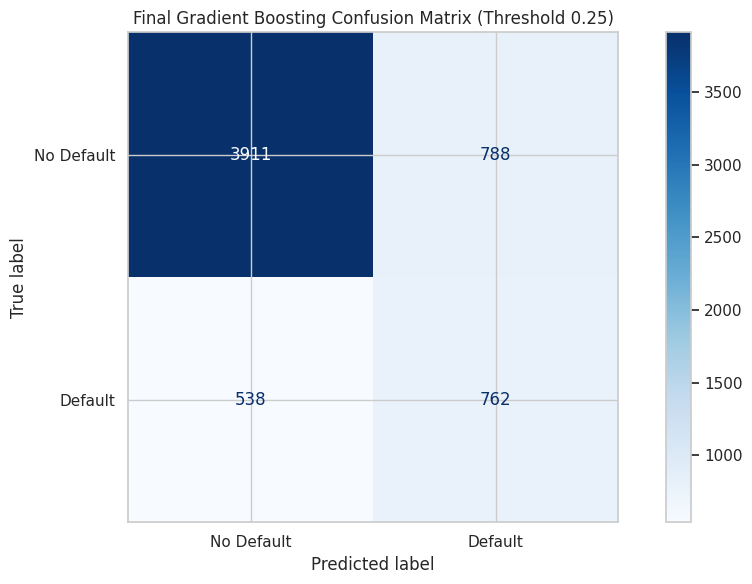

In [51]:
# Generate final confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_final,
    display_labels=['No Default', 'Default'],
    cmap='Blues',
    values_format='d'
)

plt.title('Final Gradient Boosting Confusion Matrix (Threshold 0.25)')
plt.tight_layout()
plt.show()

###  Interpretation of Recall-Focused Confusion Matrix

The final confusion matrix shows that the Gradient Boosting model correctly classified 3,911 non-default customers and 762 default customers.

It incorrectly classified 788 non-default customers as defaulters and failed to identify 538 actual defaulters.

The model achieved a recall of 58.62%, indicating that it identified approximately 58.62% of actual defaulters.

The results demonstrate the trade-off between identifying potential defaulters and minimizing false-positive predictions.

#  Accuracy Optimization

##  Threshold Optimization Using Cross-Validation

In [52]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

threshold_values = np.arange(0.20, 0.71, 0.05)
accuracy_results = []

for threshold in threshold_values:
    predictions = (gb_oof_prob >= threshold).astype(int)

    accuracy_results.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_train, predictions),
        'Precision': precision_score(y_train, predictions, zero_division=0),
        'Recall': recall_score(y_train, predictions, zero_division=0),
        'F1 Score': f1_score(y_train, predictions, zero_division=0)
    })

accuracy_df = pd.DataFrame(accuracy_results)
display(accuracy_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.20,0.7381,0.4411,0.6666,0.5309
1,0.25,0.7816,0.5076,0.5879,0.5448
2,0.30,0.8005,0.5539,0.5289,0.5411
3,0.35,0.8110,0.5949,0.4704,0.5254
4,0.40,0.8167,0.6290,0.4277,0.5091
5,0.45,0.8200,0.6566,0.3992,0.4965
6,0.50,0.8208,0.6769,0.3707,0.4791
7,0.55,0.8209,0.6953,0.3460,0.4620
8,0.60,0.8171,0.7028,0.3075,0.4278
9,0.65,0.8121,0.7232,0.2507,0.3724


In [53]:
# Select threshold based on the chosen accuracy-recall trade-off
final_threshold = 0.35

# Generate predictions on the untouched test set
final_probabilities = gb_grid_search.best_estimator_.predict_proba(X_test)[:, 1]
final_predictions = (final_probabilities >= final_threshold).astype(int)

# Evaluate final model
print("Final Threshold:", final_threshold)
print("Accuracy:", accuracy_score(y_test, final_predictions))
print("Precision:", precision_score(y_test, final_predictions))
print("Recall:", recall_score(y_test, final_predictions))
print("F1 Score:", f1_score(y_test, final_predictions))
print("ROC-AUC:", roc_auc_score(y_test, final_probabilities))

Final Threshold: 0.35
Accuracy: 0.8134689114852476
Precision: 0.5871029836381135
Recall: 0.46923076923076923
F1 Score: 0.5215904232578025
ROC-AUC: 0.7804039320968456


### Final Model Evaluation After Threshold Optimization

The tuned Gradient Boosting model was evaluated using a decision threshold of 0.35.

The threshold was selected as a compromise between overall classification accuracy and the ability to identify potential defaulters. Although higher thresholds achieved slightly better accuracy, they resulted in lower recall.

The final evaluation on the independent testing dataset produced the following results:

| Evaluation Metric | Score |
|---|---:|
| Accuracy | 81.35% |
| Precision | 58.71% |
| Recall | 46.92% |
| F1 Score | 52.16% |
| ROC-AUC | 78.04% |

**Interpretation:**

- Accuracy: The model correctly classified 81.35% of test records.
- Precision: 58.71% of customers predicted to default actually defaulted.
- Recall: The model identified 46.92% of actual defaulters.
- F1 Score: The balance between precision and recall was 52.16%.
- ROC-AUC: The model achieved 78.04%, indicating reasonable ability to distinguish between default and non-default customers.

The results demonstrate that threshold selection involves balancing the identification of potential defaulters against false-positive predictions.

**Primary model:** Tuned Gradient Boosting Classifier  
**Primary threshold:** 0.35  
**Test accuracy:** 81.35%

###  Saving the Final Optimized Model

In [56]:
# Update and save the final model artifact
import joblib
final_model = gb_grid_search.best_estimator_

model_artifact = {
    'model': final_model,
    'threshold': final_threshold,
    'feature_names': X_train.columns.tolist()
}

joblib.dump(model_artifact, 'credit_card_default_model.pkl')

print("Final model saved successfully.")
print("Decision threshold:", final_threshold)

Final model saved successfully.
Decision threshold: 0.35


###  Recall Optimization Using F2-Score

In [57]:
from sklearn.metrics import fbeta_score, precision_score, recall_score

threshold_values = np.arange(0.10, 0.71, 0.05)
recall_results = []

for threshold in threshold_values:
    predictions = (gb_oof_prob >= threshold).astype(int)

    precision = precision_score(y_train, predictions, zero_division=0)
    recall = recall_score(y_train, predictions, zero_division=0)
    f2 = fbeta_score(y_train, predictions, beta=2, zero_division=0)

    recall_results.append({
        'Threshold': round(threshold, 2),
        'Precision': precision,
        'Recall': recall,
        'F2 Score': f2
    })

recall_df = pd.DataFrame(recall_results)

# Prefer thresholds with at least 50% precision
eligible_thresholds = recall_df[recall_df['Precision'] >= 0.50]

if not eligible_thresholds.empty:
    best_recall_result = eligible_thresholds.loc[
        eligible_thresholds['F2 Score'].idxmax()
    ]
else:
    best_recall_result = recall_df.loc[
        recall_df['F2 Score'].idxmax()
    ]

display(recall_df.round(4))

print("Recommended threshold:", best_recall_result['Threshold'])
print("Expected CV precision:", round(best_recall_result['Precision'], 4))
print("Expected CV recall:", round(best_recall_result['Recall'], 4))
print("Expected CV F2 Score:", round(best_recall_result['F2 Score'], 4))

,Threshold,Precision,Recall,F2 Score
0,0.10,0.2824,0.9106,0.6302
1,0.15,0.3636,0.7755,0.6322
2,0.20,0.4411,0.6666,0.6048
3,0.25,0.5076,0.5879,0.5699
4,0.30,0.5539,0.5289,0.5337
5,0.35,0.5949,0.4704,0.4909
6,0.40,0.6290,0.4277,0.4569
7,0.45,0.6566,0.3992,0.4331
8,0.50,0.6769,0.3707,0.4076
9,0.55,0.6953,0.3460,0.3846


Recommended threshold: 0.25
Expected CV precision: 0.5076
Expected CV recall: 0.5879
Expected CV F2 Score: 0.5699


###  Final Evaluation of the Recall-Optimized Model

In [58]:
# Evaluate recall-optimized model on unseen test data

recall_threshold = 0.25

recall_probabilities = gb_grid_search.best_estimator_.predict_proba(X_test)[:, 1]

recall_predictions = (
    recall_probabilities >= recall_threshold
).astype(int)

print("Selected Threshold:", recall_threshold)
print("Accuracy:", accuracy_score(y_test, recall_predictions))
print("Precision:", precision_score(y_test, recall_predictions))
print("Recall:", recall_score(y_test, recall_predictions))
print("F1 Score:", f1_score(y_test, recall_predictions))
print("F2 Score:", fbeta_score(y_test, recall_predictions, beta=2))
print("ROC-AUC:", roc_auc_score(y_test, recall_probabilities))

Selected Threshold: 0.25
Accuracy: 0.7789631605267544
Precision: 0.4916129032258065
Recall: 0.5861538461538461
F1 Score: 0.5347368421052632
F2 Score: 0.5644444444444444
ROC-AUC: 0.7804039320968456


## Verifying the Saved Model

In [59]:
import joblib

# Load the saved model
loaded_artifact = joblib.load("credit_card_default_model.pkl")

# Extract model and threshold
loaded_model = loaded_artifact["model"]
loaded_threshold = loaded_artifact["threshold"]

# Predict using test data
sample_data = X_test.iloc[:5]

probabilities = loaded_model.predict_proba(sample_data)[:, 1]
predictions = (probabilities >= loaded_threshold).astype(int)

print("Model loaded successfully!")
print("Decision Threshold:", loaded_threshold)
print("Predictions:", predictions)
print("Actual Values:", y_test.iloc[:5].values)

Model loaded successfully!
Decision Threshold: 0.35
Predictions: [0 0 0 0 0]
Actual Values: [0 0 0 0 0]


# Conclusion and Future Scope

## Conclusion

This project developed a machine learning classification system to predict credit card payment defaults using the UCI Default of Credit Card Clients dataset.

The dataset contained 30,000 records and 23 input features. Exploratory Data Analysis was performed to understand customer characteristics, repayment patterns, credit limits, payment amounts, and relationships between variables.

Five classification algorithms were implemented and evaluated:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. K-Nearest Neighbors
5. Gradient Boosting

Gradient Boosting was selected for hyperparameter tuning based on its initial ROC-AUC and F1-score performance. Hyperparameter tuning and classification threshold optimization were performed using group-aware cross-validation to improve model evaluation and reduce data leakage from duplicate feature records.

The tuned Gradient Boosting model was selected as the final model. Using a classification threshold of **0.35**, it achieved the following results on the independent testing dataset:

- Accuracy: 81.35%
- Precision: 58.71%
- Recall: 46.92%
- F1-Score: 52.16%
- ROC-AUC: 78.04%

An alternative threshold of **0.25** was also evaluated to improve the identification of potential defaulters. At this threshold, the model achieved 77.90% accuracy, 49.16% precision, 58.62% recall, and a 53.47% F1-score.

The comparison demonstrates the trade-off between overall classification performance and identifying a larger proportion of actual defaulters. The threshold of 0.35 was retained as the primary configuration, while 0.25 provides a recall-focused alternative.

The final tuned Gradient Boosting model and its selected threshold were saved using Joblib for future use.

Overall, the project demonstrates how machine learning techniques can support credit risk assessment by identifying customers who may be more likely to default on their payments. However, the model's predictions should be treated as decision-support information rather than definitive credit decisions.

## Future Scope

The project can be enhanced through the following improvements:

1. Evaluate additional machine learning algorithms and advanced ensemble techniques.
2. Explore cost-sensitive learning to account for the financial impact of false predictions.
3. Improve recall while maintaining an acceptable precision level.
4. Use larger and more recent credit datasets to improve generalizability.
5. Develop an interactive web application for credit default prediction.
6. Evaluate model fairness, interpretability, and performance across customer groups.
7. Monitor model performance when deployed on new customer data.

## Project Limitations

1. The dataset represents credit card clients in Taiwan and may not generalize to other countries or banking environments.
2. The dataset reflects historical customer information and may not represent current credit behaviour.
3. The model produces predictions, not definitive decisions about a customer's creditworthiness.
4. The selected classification threshold involves a trade-off between false positives and false negatives.
5. The model's recall at the primary threshold of 0.35 indicates that some actual defaulters may not be identified.

In [60]:
from google.colab import files
files.download("credit_card_default_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>